Today's topics:

* figure size and resolution: `figsize` and `dpi`
* axis labels with units
* log axes for data that span decades
* saving figures as vector (PDF) and bitmap (PNG) files
* plotting code from an AI coding assistant
* checking a figure against the numbers it shows

# Battery electrolytes in the cold

Today we will turn a quick plot into a figure ready for a report.
Then we will check a figure that an AI assistant wrote.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/f1/18650_lityum_iyon_piller.jpg/960px-18650_lityum_iyon_piller.jpg" alt="A row of cylindrical 18650 lithium-ion cells with green, gray, red, yellow, purple, and turquoise wrappers standing upright on a tabletop" width=480/>

*Photo by Doğru akım enerji, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:18650_lityum_iyon_piller.jpg).*

Above: Cylindrical 18650 lithium-ion cells.

A lithium-ion battery can deliver less power in the cold.
One contribution is the electrolyte, the liquid that moves lithium ions between the electrodes.
Its conductivity falls as it cools.

The electrolyte is a lithium salt, LiPF$_6$, dissolved in organic solvents.
How much salt should we dissolve?
Does the answer change in the cold?

## The data

These are measured conductivities of LiPF$_6$ in a mix of two carbonate solvents, at 15 temperatures and 14 salt concentrations.
The concentration is a **molality**: moles of salt per kilogram of solvent.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/electrolyte_conductivity_lipf6.csv'
electrolyte = pd.read_csv(url)
display(electrolyte)

,temperature_K,molality_mol_per_kg,conductivity_mS_per_cm
0,194.15,0.2705,0.03099
1,194.15,0.3855,0.02794
2,194.15,0.4648,0.02438
3,194.15,0.5547,0.01968
4,194.15,0.6541,0.01492
...,...,...,...
205,332.15,1.4766,11.34000
206,332.15,1.7117,10.33000
207,332.15,1.9198,9.18000
208,332.15,2.1166,8.32300


How many conductivities are missing?

In [2]:
print(electrolyte['conductivity_mS_per_cm'].isna().sum())

3


So a correct figure shows 207 points.

# From a quick plot to a figure

## The quick plot

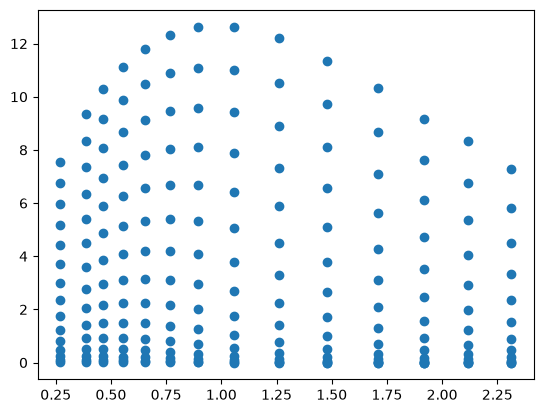

In [3]:
fig, ax = plt.subplots()
ax.scatter(electrolyte['molality_mol_per_kg'], electrolyte['conductivity_mS_per_cm'])

This is fine for a first look.
But a reader cannot tell the temperatures apart.
The axes have no labels or units.

## Size, color, and units

`figsize` sets the size of the figure in inches, width first.
`dpi` sets how many pixels make up each inch on screen.

Let's color the points by temperature in °C, as we did with `c=` and a colorbar before:

Text(0, 0.5, 'conductivity (mS cm$^{-1}$)')

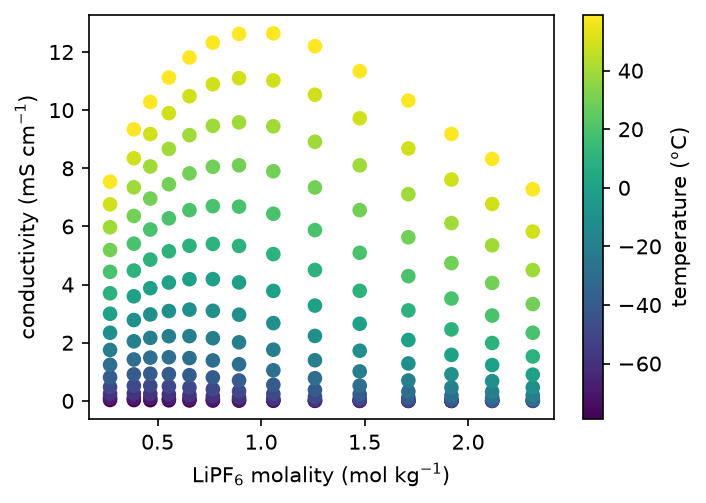

In [4]:
electrolyte['temperature_C'] = electrolyte['temperature_K'] - 273.15

fig, ax = plt.subplots(figsize=(5, 3.5), dpi=150)  # inches, pixels per inch
im = ax.scatter(electrolyte['molality_mol_per_kg'], electrolyte['conductivity_mS_per_cm'],
                c=electrolyte['temperature_C'], cmap='viridis')
cb = fig.colorbar(im, ax=ax)
cb.set_label('temperature (°C)')
ax.set_xlabel('LiPF$_6$ molality (mol kg$^{-1}$)')
ax.set_ylabel('conductivity (mS cm$^{-1}$)')

The `$...$` in a label writes a subscript with `_` and a superscript with `^`, as in our markdown.

The warm points spread out nicely.
The cold points all sit on the bottom of the plot.

What range of values are we trying to show?

In [5]:
print(electrolyte['conductivity_mS_per_cm'].min())
print(electrolyte['conductivity_mS_per_cm'].max())

9.03e-07
12.64


From about $10^{-6}$ to 12.6 mS/cm: seven orders of magnitude.
On a linear axis, everything below about 0.1 mS/cm sits on the bottom of the plot.

A log axis gives each factor of 10 the same space:

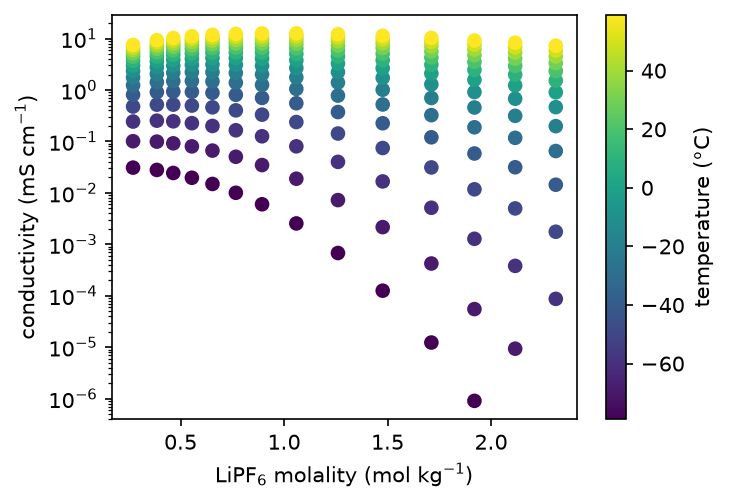

In [6]:
ax.set_yscale('log')
fig

Now we can read every temperature.
The warm series have a peak.
As the temperature drops, the peak moves to lower molality.

## Saving a figure

`fig.savefig` writes the figure to a file.
The file name's ending picks the format:

In [7]:
fig.savefig('conductivity.pdf')
fig.savefig('conductivity.png', dpi=300)

Find both files in the folder pane on the left of Colab.

A **PDF** stores lines, points, and text as shapes.
It stays sharp at any zoom.
That makes it a **vector** format.

A **PNG** stores a grid of pixels.
That makes it a **bitmap** format.
`dpi=300` gives 300 pixels per inch, a common minimum for print.

### [Check your understanding]

How does the conductivity change with temperature at a fixed salt concentration?

1. Plot conductivity against temperature in °C for each molality in `molalities` below.
   Give each series a `label=`.
2. Use a log axis for conductivity.
3. Label both axes with units and add a legend.
4. Save the figure as a PDF.

Which molality conducts best in the cold?
Does that stay true when it is warm?

In [8]:
molalities = [0.4648, 0.8937, 2.3128]  # mol/kg

# An AI coding assistant

## Asking for the figure

An AI coding assistant can write plotting code like ours in seconds.
Here is the request:

> I have a pandas DataFrame called `electrolyte` with the columns `temperature_K`, `molality_mol_per_kg`, and `conductivity_mS_per_cm`. It holds the ionic conductivity of a lithium-ion battery electrolyte (LiPF6 salt) measured at 15 temperatures and 14 salt concentrations. Write Python code with matplotlib that makes a publication-quality figure of conductivity against molality, with one series per temperature. The DataFrame is already loaded, so don't load any data. Reply with the code and a short explanation.

The reply below came from Claude Haiku 5.5 on November 15, 2026.
It ran inside the tools we use to build this course.
So it knew one of our habits: we leave out `plt.show()`.

Here is the main part of its explanation, word for word:

> Here is a matplotlib script that plots conductivity against molality, with one line per temperature coloured by temperature (viridis) and the legend outside the axes.
>
> Why it is built this way:
> - Temperature is an ordered quantity, so one sequential colormap (viridis) runs from cool to warm and the reader can see the trend across lines.
> - The legend sits outside the plot so the 15 lines are not hidden behind it.
> - Each line is sorted by molality so it does not zigzag, and small markers show the measured points without cluttering the figure.
> - The colormap is truncated at 0.9 so the palest yellow does not wash out against white.
> - The PDF is vector with editable text, and the PNG is at 600 dpi for slides or a manuscript.
> - There is no `plt.show()`, as you prefer.

And here is its code, unchanged.
It uses tools we have not covered, and that is normal for assistant code.

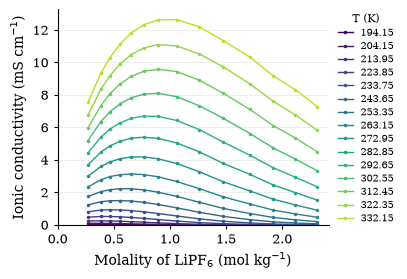

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "legend.frameon": False,
    "legend.fontsize": 7,
    "legend.title_fontsize": 8,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,  # keep text editable in vector output
})

cmap = plt.colormaps["viridis"]
temps = np.sort(electrolyte["temperature_K"].unique())
norm = Normalize(vmin=temps.min(), vmax=temps.max())

fig, ax = plt.subplots(figsize=(3.5, 2.8))  # single-column width

for T in temps:
    sub = (electrolyte[electrolyte["temperature_K"] == T]
           .dropna(subset=["molality_mol_per_kg", "conductivity_mS_per_cm"])
           .sort_values("molality_mol_per_kg"))
    # Truncate the colormap so the palest yellow end stays visible on white
    color = cmap(0.9 * norm(T))
    ax.plot(sub["molality_mol_per_kg"], sub["conductivity_mS_per_cm"],
            color=color, lw=1.0, marker="o", ms=2.5, mec="none",
            label=f"{T:g}")

ax.set_xlabel(r"Molality of LiPF$_6$ (mol kg$^{-1}$)")
ax.set_ylabel(r"Ionic conductivity (mS cm$^{-1}$)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9", lw=0.5)
ax.set_axisbelow(True)

ax.legend(title="T (K)", loc="upper left", bbox_to_anchor=(1.02, 1),
          borderaxespad=0, handlelength=1.5, labelspacing=0.3)

fig.savefig("conductivity_vs_molality.pdf", bbox_inches="tight")
fig.savefig("conductivity_vs_molality.png", bbox_inches="tight")

It looks finished.
The labels have units, the colors run in order, and it saved two files.

`plt.rcParams.update` also changed the defaults for every later figure in this notebook, like the serif font.
`plt.rcdefaults()` puts them back:

In [10]:
plt.rcdefaults()

### [Check your understanding]

Is the assistant's figure right?
Check it against the numbers, not against how it looks.

1. Print `ax.get_yscale()` and `ax.get_ylim()` for the assistant's axes.
2. Compare them with the smallest and largest conductivity we printed earlier.

Which temperatures can a reader not read from this figure?
Which line of the assistant's code would you change, and to what?

A log axis cannot start at 0.

# How much salt?

Let's find the best molality at about 29 °C and at about $-39$ °C:

In [11]:
warm = electrolyte[electrolyte['temperature_K'] == 302.55]
cold = electrolyte[electrolyte['temperature_K'] == 233.75]

display(warm.sort_values(by='conductivity_mS_per_cm', ascending=False).head(1))
display(cold.sort_values(by='conductivity_mS_per_cm', ascending=False).head(1))

,temperature_K,molality_mol_per_kg,conductivity_mS_per_cm,temperature_C
160,302.55,0.8937,8.101,29.4


,temperature_K,molality_mol_per_kg,conductivity_mS_per_cm,temperature_C
58,233.75,0.4648,0.9339,-39.4


At 29 °C the highest conductivity is at 0.89 mol/kg.
At $-39$ °C it is at 0.46 mol/kg, about half.

For this solvent mixture, an electrolyte meant for the cold would conduct best with less salt.
On the assistant's linear figure, the cold peak was invisible.

## Writing the caption

A caption says what is plotted, where the data came from, and how the figure was made:

> **Figure 1.** Conductivity of LiPF$_6$ in propylene carbonate and diethyl carbonate (50:50 by mass) against molality, colored by temperature from $-79$ °C to 59 °C (log scale).
> Data from M. S. Ding, *J. Chem. Eng. Data* 48, 519–528 (2003), [doi:10.1021/je020219o](https://doi.org/10.1021/je020219o), via the CALiSol-23 database (de Blasio et al., *Scientific Data* 11, 750 (2024), [doi:10.1038/s41597-024-03575-8](https://doi.org/10.1038/s41597-024-03575-8), CC BY 4.0).
> Plotting code drafted by Claude Haiku 5.5 and checked against the data; the conductivity axis was changed to a log scale.

# Summary

* `plt.subplots(figsize=(w, h), dpi=...)` sets the figure size in inches and its pixels per inch.
* Label each axis with its quantity and units; `$...$` writes subscripts and superscripts.
* A log axis shows data that span several orders of magnitude.
* `fig.savefig('name.pdf')` saves a vector figure; `fig.savefig('name.png', dpi=300)` saves a bitmap.
* Check an AI assistant's figure against the numbers: scale, limits, point count, units.
* Report which AI tool you used and what you asked it.

## Further reading

* Matplotlib, [`Figure.savefig`](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html)
* Matplotlib, [Axis scales](https://matplotlib.org/stable/gallery/scales/scales.html)
* Photo credit: 18650 lithium-ion cells, Doğru akım enerji, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:18650_lityum_iyon_piller.jpg)